# 8. Estimating more

> Extend the estimation problem beyond position and velocity: estimate an SRP scale factor, account for an unestimated parameter with a consider covariance, reject outliers with measurement editing, and compare tracking scenarios with covariance analysis.
>
> ⏱ ~15 min &nbsp;·&nbsp; **Prereqs:** [7. Sequential filtering & process noise](07_sequential_filtering.ipynb) &nbsp;·&nbsp; **Uses:** `outputs/02_truth_dynamics/truth.bsp`, `outputs/03_tracking_data/*.json` &nbsp;·&nbsp; **Next:** [9. Tracking data II: real DSN data](09_real_dsn_data.ipynb)

[Chapter 7](07_sequential_filtering.ipynb) used process noise to absorb a missing acceleration statistically. When the form of the error is known, it can instead be modeled: either estimated as part of the state, or carried as a known uncertainty. This chapter does both for solar radiation pressure, then covers two other everyday tools: measurement editing and covariance analysis.

## Setup

The scenario, the measurement models from [chapter 5](05_filter_measurements.ipynb), and the a-priori state from [chapter 4](04_filter_dynamics.ipynb). All of it comes from [`scenario.py`](scenario.py). The filter's spacecraft properties change between sections, so each run passes its spacecraft and state to `reference_propagator()`.

**Starting here?** This chapter reads the outputs of chapters [2](02_truth_dynamics.ipynb) and [3](03_tracking_data.ipynb). Run `python prepare.py 08` from `tutorials/v2/` to generate them (about 15 s); the setup cell stops with a message if they are missing.

In [1]:
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import scarabaeus as scb

from scenario import (
    kg, km, m, minute, day, J2000,       # units, frame
    epochs, orex, mass, cr,              # tracking arc, truth spacecraft and its properties (ch. 1-2)
    models, TRACKING_DIR,                # measurement models (ch. 3)
    reference, apriori_state,            # the correctly sized filter spacecraft and a-priori state (ch. 4)
    r_apriori, v_apriori, P0,
    apriori_sigmas as sigma_apriori,
    reference_propagator,
)

out = Path("outputs/08_estimating_more")
shutil.rmtree(out, ignore_errors=True)
out.mkdir(parents=True)
tracking_dir = Path(TRACKING_DIR)  # produced by chapter 3

# Inputs from earlier chapters. Starting here? Run `python prepare.py 08` first.
if not (Path("outputs/02_truth_dynamics/truth.bsp").exists() and len(list(tracking_dir.glob("*.json"))) == 6):
    raise FileNotFoundError(
        "This chapter reads the truth trajectory (chapter 2) and the tracking data (chapter 3). "
        "Run those chapters, or `python prepare.py 08` from tutorials/v2/ (about 15 s)."
    )

scb.SpiceManager.load_kernel("outputs/02_truth_dynamics/truth.bsp")  # truth (ch. 2)

# --- the tracking data (chapters 3 and 5) ---
observed = {model.name: model.observed_measurements(str(tracking_dir / f"{model.name.replace(' ', '_')}.json"),
                                                    units=model.sigma.units)
            for model in models}
tracking = scb.MeasurementSpec.many(*[
    scb.MeasurementSpec(model=model, observed_meas=observed[model.name], dataset_name=model.name) for model in models
])


## 1. A mis-sized SRP model

The truth uses an SRP area of 11 m². Suppose the filter's spacecraft model assumes 15 m², a 36% error in the SRP acceleration. Everything else is unchanged:

In [2]:
%%capture fit_log
# 🔵 TODO: remove %%capture once filters and measurement models stop printing progress
reference_15 = scb.Spacecraft("OREx reference", -64001, mass, scb.ArrayWUnits(15.0, m**2).convert_to(km**2), cr)

state = (scb.StateDefinition()
         .position(reference_15, scb.ArrayWFrame(r_apriori, J2000))
         .velocity(reference_15, scb.ArrayWFrame(v_apriori, J2000)))

srifb = scb.SRIFB(propagator=reference_propagator(reference_15, state), measurements=tracking,
                  settings=scb.FilterSettings(initial_covariance=P0), traj_name="wrong_area.bsp", traj_dir=str(out))
solution_wrong, _, _ = srifb.fit(traj_name="wrong_area.bsp", traj_dir=str(out), convergence_threshold=1e-5)

In [3]:
t_first = scb.EpochArray(solution_wrong.timestamps[:1], sys="TDB")
x_true_first = orex.get_state(t_first[0], reference_frame="J2000", origin="SUN").quantity.values

dr = solution_wrong.state_est[0, :3] - x_true_first[:3]
sigma_r = sum(solution_wrong.covariance_est[0].diagonal()[:3]) ** 0.5
print(f"position error {(dr @ dr) ** 0.5:.1f} km, reported 1σ {sigma_r:.2f} km (RSS, first measurement epoch)")

position error 21.9 km, reported 1σ 1.57 km (RSS, first measurement epoch)


As in [chapter 7](07_sequential_filtering.ipynb), the dynamics error is absorbed into the poorly observed directions of the state: the estimate is about 14σ off.

## 2. Estimating the SRP scale factor

The SRP acceleration in Scarabaeus includes a scale factor $\eta_\text{SRP}$ (default 1) that multiplies $C_R A / m$. Adding `eta_srp` to the state as a **static, estimated** parameter lets the filter solve for it together with position and velocity. Its a-priori value is 1 with a loose 1σ of 0.5, appended to the a-priori covariance; it has no units:

In [4]:
%%capture fit_log
# 🔵 TODO: remove %%capture once filters and measurement models stop printing progress
state_eta = (scb.StateDefinition()
             .position(reference_15, scb.ArrayWFrame(r_apriori, J2000))
             .velocity(reference_15, scb.ArrayWFrame(v_apriori, J2000))
             .param("eta_srp", reference_15, scb.ArrayWFrame(scb.ArrayWUnits([1.0], None), J2000),
                    estimation="estimated", dynamics="static"))
P0_eta = scb.CovarianceMatrix(sigma_apriori + [scb.ArrayWUnits(0.5, None)], epochs[0], from_list=True)

srifb_eta = scb.SRIFB(propagator=reference_propagator(reference_15, state_eta), measurements=tracking,
                      settings=scb.FilterSettings(initial_covariance=P0_eta), traj_name="eta.bsp", traj_dir=str(out))
solution_eta, n_eta, _ = srifb_eta.fit(traj_name="eta.bsp", traj_dir=str(out), convergence_threshold=1e-5)

In [5]:
eta_hat = solution_eta.state_est[0, 6]
sigma_eta = solution_eta.covariance_est[0][6, 6] ** 0.5
dr = solution_eta.state_est[0, :3] - x_true_first[:3]
print(f"η_SRP = {eta_hat:.4f} ± {sigma_eta:.4f}   (truth: 11/15 = {11 / 15:.4f}), converged in {n_eta} iterations")
print(f"position error {(dr @ dr) ** 0.5:.2f} km, reported 1σ {sum(solution_eta.covariance_est[0].diagonal()[:3]) ** 0.5:.2f} km")

η_SRP = 0.7325 ± 0.0253   (truth: 11/15 = 0.7333), converged in 2 iterations
position error 0.63 km, reported 1σ 2.59 km


/Users/andrealopez/Documents/Research/scarabaeus/src/scarabaeus/timeAndFrame/SpiceManager.py:1440: RuntimeWarning: Multiple matching JSON files found. Using most recently modified file: eta_it2_parameters.json
  warnings.warn(


<div style="border-left:4px solid #dc2626; background:rgba(220,38,38,0.12); padding:6px 10px; border-radius:4px">
🔴 <b>FIX:</b> Reading <code>state_est</code> after a run with parameters prints <code>RuntimeWarning: Multiple matching JSON files found</code>: the estimated state is reconstructed from the reference SPK and its <code>_parameters.json</code> sidecar, and the sidecar lookup matches every iteration's file by pattern and picks the most recently modified one. The result is correct here, but the lookup should use the exact file name.
</div>

The filter recovers the scale factor that corrects the SRP area, to within a small fraction of its 1σ, and the position error returns to the level of [chapter 6](06_first_od_solution.ipynb). The price is a larger position uncertainty: the data now have to determine one more parameter, which is correlated with the state. The state vector has seven components, so `state_est` and `covariance_est` grow accordingly.

## 3. Consider parameters

Sometimes a parameter should not be estimated, for example because it is poorly observable from a short arc or because its value is fixed by an external calibration, yet its uncertainty is real. A **consider** parameter (Schmidt) keeps its a-priori value but propagates its uncertainty into the covariance of the estimated states. It is declared with `estimation="considered"`; here the scale factor is left at 1 with a 1σ uncertainty of 0.3:

In [6]:
%%capture fit_log
# 🔵 TODO: remove %%capture once filters and measurement models stop printing progress
state_consider = (scb.StateDefinition()
                  .position(reference_15, scb.ArrayWFrame(r_apriori, J2000))
                  .velocity(reference_15, scb.ArrayWFrame(v_apriori, J2000))
                  .param("eta_srp", reference_15, scb.ArrayWFrame(scb.ArrayWUnits([1.0], None), J2000),
                         estimation="considered", dynamics="static"))
P0_consider = scb.CovarianceMatrix(sigma_apriori + [scb.ArrayWUnits(0.3, None)], epochs[0], from_list=True)

srifb_consider = scb.SRIFB(propagator=reference_propagator(reference_15, state_consider), measurements=tracking,
                           settings=scb.FilterSettings(initial_covariance=P0_consider),
                           traj_name="consider.bsp", traj_dir=str(out))
solution_consider, _, _ = srifb_consider.fit(traj_name="consider.bsp", traj_dir=str(out), convergence_threshold=1e-5)

In [7]:
dr = solution_consider.state_est[0, :3] - x_true_first[:3]
sigma_r_consider = sum(solution_consider.covariance_consider[0].diagonal()[:3]) ** 0.5
print(f"η_SRP kept at {solution_consider.state_est[0, 6]:.1f}")
print(f"position error {(dr @ dr) ** 0.5:.1f} km, consider 1σ {sigma_r_consider:.1f} km "
      f"→ {(dr @ dr) ** 0.5 / sigma_r_consider:.2f} σ")

η_SRP kept at 1.0
position error 21.9 km, consider 1σ 24.4 km → 0.90 σ


/Users/andrealopez/Documents/Research/scarabaeus/src/scarabaeus/timeAndFrame/SpiceManager.py:1440: RuntimeWarning: Multiple matching JSON files found. Using most recently modified file: consider_it2_parameters.json
  warnings.warn(


<div style="border-left:4px solid #dc2626; background:rgba(220,38,38,0.12); padding:6px 10px; border-radius:4px">
🔴 <b>FIX:</b> In runs with consider parameters, <code>solution.covariance_est</code> (the data-noise-only covariance) has small negative velocity variances and is not positive semi-definite. <code>covariance_consider</code> is consistent with the actual errors and is used below.
</div>

The estimate is the same as in section 1, since $\eta_\text{SRP}$ was not adjusted, but the covariance is now honest about it: the 22 km error is within the consider uncertainty. The three approaches side by side, over the tracking week and three days past it. `propagate_state_covariance` maps each solution to any epoch, including the consider covariance when there is one:

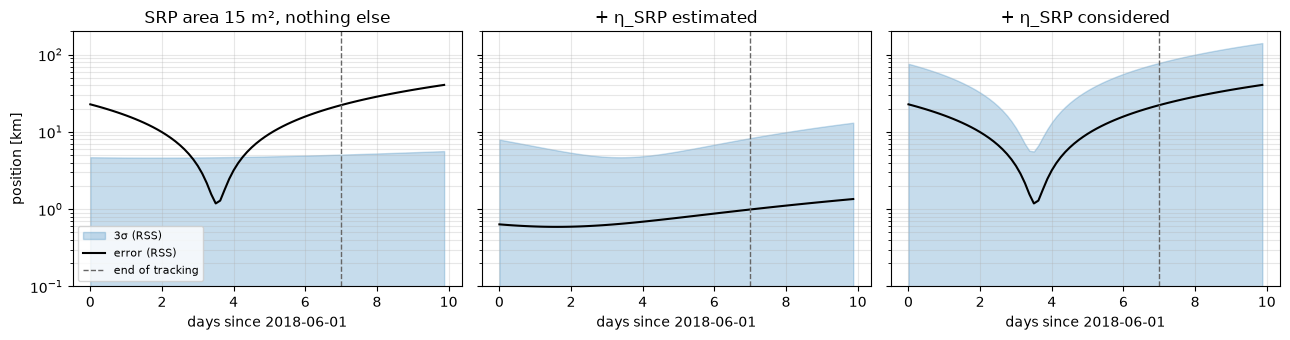

In [8]:
t_compare = scb.EpochArray.interval(
    scb.SpiceManager.utc2et("2018-06-01T00:00:00"),
    scb.SpiceManager.utc2et("2018-06-11T00:00:00"),
    dt=scb.ArrayWUnits(180, minute),
    sys="TDB",
)
# TODO(draft): get_state takes one epoch at a time; replace the loop once it accepts an EpochArray
r_true = np.array([orex.get_state(t, reference_frame="J2000", origin="SUN").quantity.values[:3] for t in t_compare])
t_days = (t_compare - epochs[0]).convert_to(day).values

runs = {
    "SRP area 15 m², nothing else": solution_wrong,
    "+ η_SRP estimated": solution_eta,
    "+ η_SRP considered": solution_consider,
}
# 🔵 TODO: use Plotting.plot_compare_state_error_norm once it draws one σ band per solution (scb_suggestions.md 6.71)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for a, (label, solution) in zip(ax, runs.items()):
    predicted = solution.propagate_state_covariance(t_compare)
    error = np.linalg.norm(np.array([state.values0.values[:3] for state, _ in predicted]) - r_true, axis=1)
    sigma3 = 3 * np.sqrt([np.trace(P[:3, :3]) for _, P in predicted])
    a.fill_between(t_days, 1e-2, sigma3, color="C0", alpha=0.25, label="3σ (RSS)")
    a.plot(t_days, error, "k", label="error (RSS)")
    a.axvline(7, color="0.4", ls="--", lw=1, label="end of tracking")
    a.set(title=label, xlabel="days since 2018-06-01", yscale="log", ylim=(0.1, 200))
    a.grid(alpha=0.3, which="both")
ax[0].set(ylabel="position [km]")
ax[0].legend(fontsize=8, loc="lower left")
plt.tight_layout()

Ignoring the error, the estimate is 22 km off at the start of the arc and about 40 km off by June 11, against a 3σ of about 5 km. The error passes close to zero in the middle of the week, where the fit balances the wrong SRP acceleration across the arc; that is also why the residuals barely show it. Estimating $\eta_\text{SRP}$ keeps the error near 1 km and inside the bounds, three days into the prediction included. Considering it leaves the estimate exactly as wrong as in the first panel, but the consider covariance grows with the error and covers it everywhere, at the price of a 3σ of up to about 150 km.

At the first measurement epoch:

| Filter model | Position error | 1σ | Error / σ |
|---|---|---|---|
| SRP area 15 m², nothing else | ~22 km | ~1.6 km | ~14 |
| + $\eta_\text{SRP}$ estimated | sub-km | ~2.6 km | < 1 |
| + $\eta_\text{SRP}$ considered | ~22 km | ~24 km (consider) | < 1 |

Estimating corrects the state; considering only makes the uncertainty realistic. Considering is the right choice when estimating would fit noise, or when the parameter is not the filter's to adjust.

## 4. Measurement editing

Real tracking data contain occasional bad points. To see their effect, four DSS-43 range observations are corrupted by +50 m (25σ) and the original filter (correct SRP model) is run on the result:

In [9]:
%%capture fit_log
# 🔵 TODO: remove %%capture once filters and measurement models stop printing progress
state = apriori_state  # the correctly sized reference spacecraft (11 m²), from scenario.py

corrupted_values = observed["DSS-43 range"].meas_obs.quantity.values.copy()
bad = [20, 60, 100, 140]
corrupted_values[bad] += scb.ArrayWUnits(50.0, m).convert_to(km).values
corrupted = dict(observed)
corrupted["DSS-43 range"] = observed["DSS-43 range"]._replace(meas_obs=scb.ArrayWFrame(scb.ArrayWUnits(corrupted_values, km), J2000))
tracking_corrupted = scb.MeasurementSpec.many(*[
    scb.MeasurementSpec(model=model, observed_meas=corrupted[model.name], dataset_name=model.name) for model in models
])

srifb_bad = scb.SRIFB(propagator=reference_propagator(reference, state), measurements=tracking_corrupted,
                      settings=scb.FilterSettings(initial_covariance=P0), traj_name="outliers.bsp", traj_dir=str(out))
solution_bad, _, _ = srifb_bad.fit(traj_name="outliers.bsp", traj_dir=str(out), convergence_threshold=1e-5)

In [10]:
dr = solution_bad.state_est[0, :3] - x_true_first[:3]
postfit = solution_bad.postfits["DSS-43 range"]
print(f"position error {(dr @ dr) ** 0.5:.2f} km, reported 1σ {sum(solution_bad.covariance_est[0].diagonal()[:3]) ** 0.5:.2f} km")
print("post-fit residuals at the corrupted points [σ]:", [round(float(postfit[i][0] / postfit[i][1]), 1) for i in bad])

position error 5.12 km, reported 1σ 1.57 km
post-fit residuals at the corrupted points [σ]: [22.7, 26.1, 24.6, 24.0]


Four points out of 632 move the solution by several kilometers, about 3σ, and stand out clearly in the post-fit residuals. `FilterSettings` can reject such points automatically. With `editing_method="chi2"`, observations whose normalized residual exceeds `sigma_scale` are flagged and excluded:

<div style="border-left:4px solid #dc2626; background:rgba(220,38,38,0.12); padding:6px 10px; border-radius:4px">
🔴 <b>FIX:</b> Editing is applied to the residuals of every iteration, including the first, and flags accumulate. On the a-priori reference all 632 pre-fit residuals exceed 4σ, so enabling editing on the first pass flags every observation and the fit fails. Until editing skips the first iteration (or works on post-fit residuals), edit in a second pass that starts from a converged solution, as below.
</div>

In [11]:
%%capture fit_log
# 🔵 TODO: remove %%capture once filters and measurement models stop printing progress
x_pass1 = reference.get_state(epochs[0], reference_frame="J2000", origin="SUN").quantity   # converged pass-1 estimate
state_pass2 = (scb.StateDefinition()
               .position(reference, scb.ArrayWFrame(x_pass1[:3], J2000))
               .velocity(reference, scb.ArrayWFrame(x_pass1[3:], J2000)))
editing = scb.FilterSettings(initial_covariance=P0, editing_method="chi2",
                             editing_kwargs={"sigma_scale": 4.0, "preview": False})

srifb_edit = scb.SRIFB(propagator=reference_propagator(reference, state_pass2), measurements=tracking_corrupted,
                       settings=editing, traj_name="edited.bsp", traj_dir=str(out))
solution_edit, _, _ = srifb_edit.fit(traj_name="edited.bsp", traj_dir=str(out), convergence_threshold=1e-5)

In [12]:
for dataset in srifb_edit.measurement_data.datasets:
    flagged = [i for i, flag in enumerate(dataset.data["outlier_flag"]) if flag]
    if flagged:
        print(f"{dataset.set_name}: rejected observations {flagged} (corrupted: {bad})")

dr = solution_edit.state_est[0, :3] - x_true_first[:3]
print(f"position error {(dr @ dr) ** 0.5:.2f} km, reported 1σ {sum(solution_edit.covariance_est[0].diagonal()[:3]) ** 0.5:.2f} km")

DSS-43 range: rejected observations [20, 60, 100, 140] (corrupted: [20, 60, 100, 140])
position error 0.75 km, reported 1σ 1.57 km


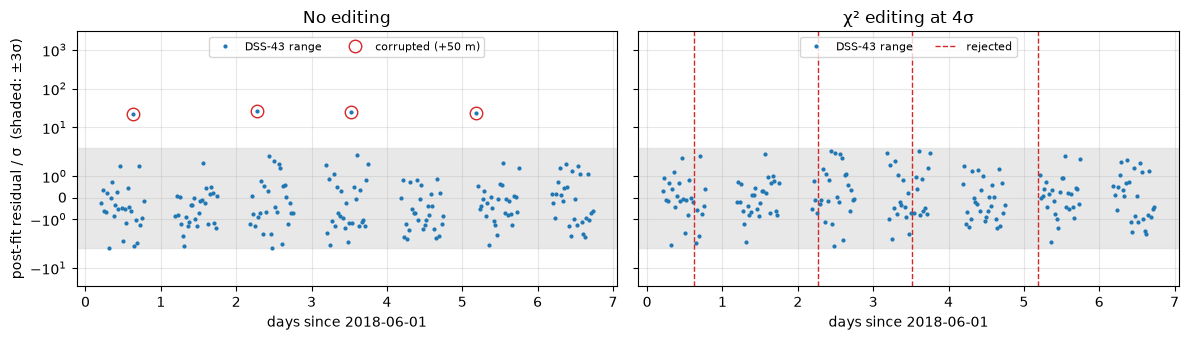

In [13]:
t_obs = observed["DSS-43 range"].meas_time_et
t_obs_days = (t_obs - epochs[0]).convert_to(day).values
rejected = np.array(next(d.data["outlier_flag"] for d in srifb_edit.measurement_data.datasets
                         if d.set_name == "DSS-43 range"), dtype=bool)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
z = np.array([r / s for r, s, *_ in solution_bad.postfits["DSS-43 range"]])
ax[0].plot(t_obs_days, z, ".", ms=4, label="DSS-43 range")
ax[0].plot(t_obs_days[bad], z[bad], "o", mfc="none", mec="C3", ms=9, label="corrupted (+50 m)")
ax[0].set(title="No editing")

z = np.array([r / s for r, s, *_ in solution_edit.postfits["DSS-43 range"]])  # rejected points have no post-fit
ax[1].plot(t_obs_days[~rejected], z, ".", ms=4, label="DSS-43 range")
for k, t in enumerate(t_obs_days[rejected]):
    ax[1].axvline(t, color="C3", ls="--", lw=1, label="rejected" if k == 0 else None)
ax[1].set(title="χ² editing at 4σ")

for a in ax:
    a.axhspan(-3, 3, color="0.85", alpha=0.6, zorder=0)
    a.set(xlabel="days since 2018-06-01", yscale="symlog", ylim=(-30, 3000))
    a.legend(fontsize=8, loc="upper center", ncol=2)
    a.grid(alpha=0.3)
ax[0].set(ylabel="post-fit residual / σ  (shaded: ±3σ)")
plt.tight_layout()

Without editing, the four corrupted points sit at about 25σ while the rest look like ordinary noise, which is what makes them easy to catch. With editing, the rejected observations get no weight and no post-fit residual (the dashed lines mark their epochs), and every remaining residual is within 3σ.

The editor rejects exactly the corrupted observations, and the solution returns to the level of [chapter 6](06_first_od_solution.ipynb). Other editing methods (`"date_range"`, and the interactive `"lasso"` and `"interactive_date_range"`) use the same settings fields; `editing_datasets` restricts editing to selected datasets. The editing step is also available on its own as `MeasurementEditing`.

→ *Model catalogs: Measurement editing*

## 5. Covariance analysis

Covariance analysis predicts the uncertainty a tracking plan would produce, without any measurements: only the epochs and the measurement models are needed. It is the standard tool for comparing tracking schedules before data exist. With `FilterSettings(covariance_analysis=True)`, each `MeasurementSpec` is given `epochs=` instead of `observed_meas=`, and `fit()` makes a single pass that skips the state update. Here the epochs come from the [chapter 3](03_tracking_data.ipynb) schedule; in a planning study they would come from visibility analysis ([chapter 1](01_scenario.ipynb)). Three scenarios:

In [14]:
%%capture fit_log
# 🔵 TODO: remove %%capture once filters and measurement models stop printing progress
scenarios = {
    "all three complexes, range + range-rate": lambda model: True,
    "without Canberra (DSS-43)": lambda model: "DSS-43" not in model.name,
    "range only": lambda model: isinstance(model, scb.RangeIdeal),
}
predictions = {}
for label, use in scenarios.items():
    plan = scb.MeasurementSpec.many(*[
        scb.MeasurementSpec(model=model, epochs=observed[model.name][0], dataset_name=model.name)
        for model in models if use(model)
    ])
    analysis = scb.SRIFB(propagator=reference_propagator(reference, state), measurements=plan,
                         settings=scb.FilterSettings(initial_covariance=P0, covariance_analysis=True),
                         traj_name="covariance_analysis.bsp", traj_dir=str(out))
    predictions[label] = analysis.fit(traj_name="covariance_analysis.bsp", traj_dir=str(out))[0]

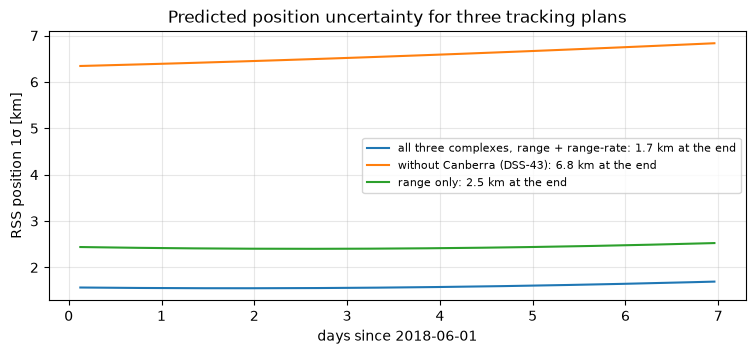

In [15]:
fig, ax = plt.subplots(figsize=(9, 3.5))
for label, prediction in predictions.items():
    t_days = (scb.EpochArray(prediction.timestamps, sys="TDB") - epochs[0]).convert_to(day).values
    sigma = [sum(P.diagonal()[:3]) ** 0.5 for P in prediction.covariance_est]
    ax.plot(t_days, sigma, label=f"{label}: {sigma[-1]:.1f} km at the end")
ax.set(xlabel="days since 2018-06-01", ylabel="RSS position 1σ [km]", title="Predicted position uncertainty for three tracking plans")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

The first scenario reproduces the uncertainty of the actual [chapter 6](06_first_od_solution.ipynb) solution, as it should: with matching models the formal covariance does not depend on the measurement values. Dropping Canberra, which provides most of the tracking at this declination, roughly quadruples the uncertainty, and removing range-rate costs about 50%.

## Summary

| Concept | Scarabaeus API |
|---|---|
| SRP scale factor | `StateDefinition.param("eta_srp", spacecraft, value, estimation="estimated", dynamics="static")` |
| A-priori for parameters | extra σ entries in `CovarianceMatrix([...], epoch, from_list=True)` |
| Consider parameters | `estimation="considered"`, `SolutionOD.covariance_consider` |
| Measurement editing | `FilterSettings(editing_method="chi2", editing_kwargs={"sigma_scale": ...})`, flags in `filter.measurement_data.datasets` |
| Comparing solutions in and past the arc | `SolutionOD.propagate_state_covariance(epochs)` (includes the consider covariance) |
| Covariance analysis | `FilterSettings(covariance_analysis=True)`, `MeasurementSpec(model, epochs=..., dataset_name=...)` |

**Next:** [9. Tracking data II: real DSN data](09_real_dsn_data.ipynb) replaces the simulated measurements with the real OSIRIS-REx tracking pass from June 8, 2018.